   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 1.3 MB/s eta 0:00:00
Signal shape: (650000, 2)
Sampling frequency: 360
Lead names: ['MLII', 'V5']


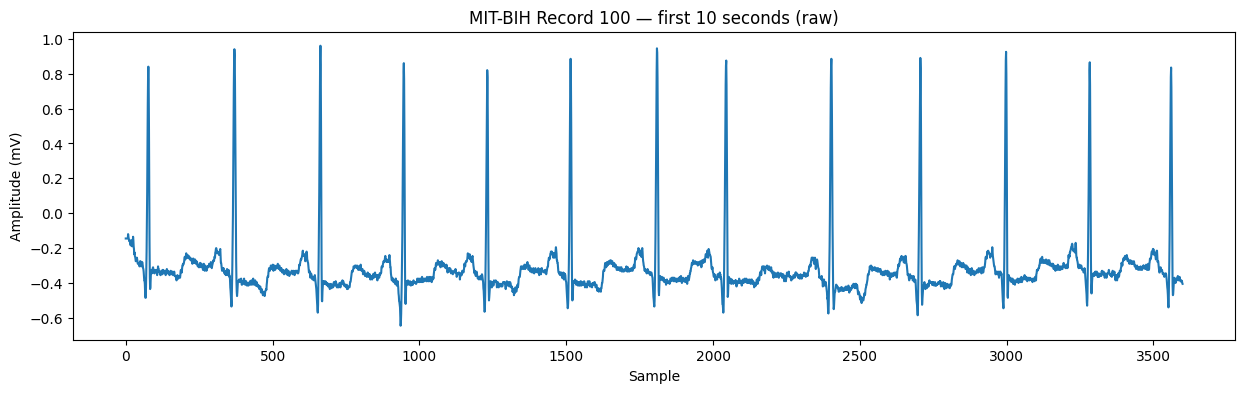

In [5]:
!pip install wfdb -q

import wfdb
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from scipy.signal import find_peaks

# Load record 100 from MIT-BIH
record = wfdb.rdrecord('100', pn_dir='mitdb')
annotation = wfdb.rdann('100', 'atr', pn_dir='mitdb')

fs = record.fs
ecg_raw = record.p_signal[:, 0]

print("Signal shape:", record.p_signal.shape)
print("Sampling frequency:", fs)
print("Lead names:", record.sig_name)

plt.figure(figsize=(15, 4))
plt.plot(ecg_raw[:fs*10])
plt.title("MIT-BIH Record 100 — first 10 seconds (raw)")
plt.xlabel("Sample")
plt.ylabel("Amplitude (mV)")
plt.show()


Number of R-peaks detected: 2289
Beats in first 10 seconds: 13 -> approx HR: 78 bpm


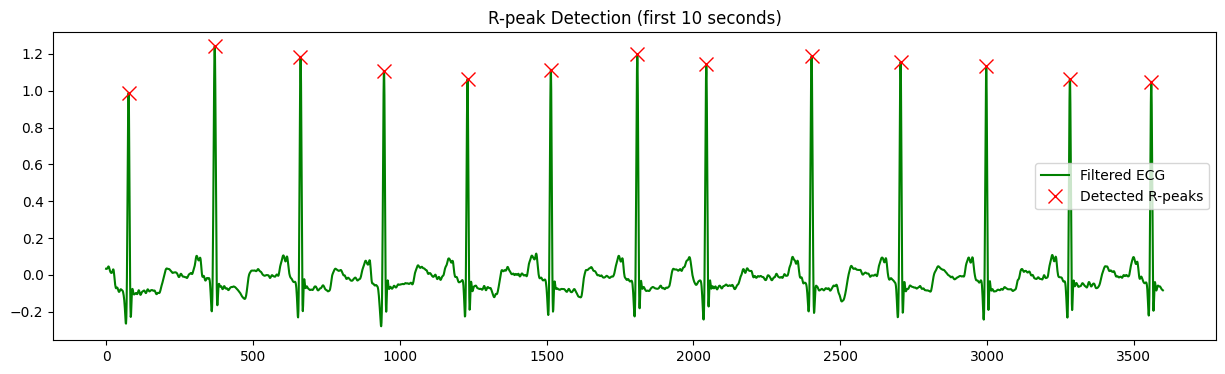

In [6]:
def bandpass_filter(sig, fs, low=0.5, high=40, order=4):
    nyq = 0.5 * fs
    b, a = signal.butter(order, [low/nyq, high/nyq], btype='band')
    return signal.filtfilt(b, a, sig)

ecg_filtered = bandpass_filter(ecg_raw, fs)

min_distance = int(0.25 * fs)
peaks, _ = find_peaks(ecg_filtered, distance=min_distance,
                       height=np.mean(ecg_filtered) + 0.4*np.std(ecg_filtered))

print("Number of R-peaks detected:", len(peaks))
peaks_in_10s = peaks[peaks < fs*10]
print(f"Beats in first 10 seconds: {len(peaks_in_10s)} -> approx HR: {len(peaks_in_10s)*6} bpm")

plt.figure(figsize=(15, 4))
plt.plot(ecg_filtered[:fs*10], color='green', label='Filtered ECG')
plt.plot(peaks_in_10s, ecg_filtered[peaks_in_10s], 'rx', markersize=10, label='Detected R-peaks')
plt.title("R-peak Detection (first 10 seconds)")
plt.legend()
plt.show()

In [7]:
import wfdb
record = wfdb.rdrecord('100',pn_dir='mitdb')
annotation = wfdb.rdann('100','atr',pn_dir='mitdb')
fs = record.fs
ecg_raw = record.p_signal[:, 0]

In [8]:

# --- Map annotation symbols to Normal (0) vs Abnormal (1) ---
def label_beat(symbol):
    return 0 if symbol == 'N' else 1

ann_samples = annotation.sample   # sample index of each annotated beat
ann_symbols = annotation.symbol   # beat type at each index

print("Total annotated beats:", len(ann_samples))
print("Unique beat types found:", set(ann_symbols))

from collections import Counter
print("Beat type counts:", Counter(ann_symbols))

Total annotated beats: 2274
Unique beat types found: {'+', 'N', 'A', 'V'}
Beat type counts: Counter({'N': 2239, 'A': 33, '+': 1, 'V': 1})


In [9]:
record_names = ['100', '101', '103', '108', '200', '203', '210', '221']

all_records = {}
for rname in record_names:
    rec = wfdb.rdrecord(rname, pn_dir='mitdb')
    ann = wfdb.rdann(rname, 'atr', pn_dir='mitdb')
    all_records[rname] = {'record': rec, 'annotation': ann}
    print(f"Loaded {rname}: {len(ann.sample)} annotated beats")

# Combined beat type counts across all 8 records
all_symbols = []
for rname in record_names:
    all_symbols.extend(all_records[rname]['annotation'].symbol)

print("\nCombined beat type counts:", Counter(all_symbols))

Loaded 100: 2274 annotated beats
Loaded 101: 1874 annotated beats
Loaded 103: 2091 annotated beats
Loaded 108: 1824 annotated beats
Loaded 200: 2792 annotated beats
Loaded 203: 3108 annotated beats
Loaded 210: 2685 annotated beats
Loaded 221: 2462 annotated beats

Combined beat type counts: Counter({'N': 16646, 'V': 1878, '+': 237, '~': 180, 'A': 72, '|': 39, 'a': 24, 'F': 15, 'x': 11, 'Q': 6, 'j': 1, 'E': 1})


In [10]:
def bandpass_filter(sig, fs, low=0.5, high=40, order=4):
    nyq = 0.5 * fs
    b, a = signal.butter(order, [low/nyq, high/nyq], btype='band')
    return signal.filtfilt(b, a, sig)

# Symbols that count as real heartbeats (exclude rhythm/artifact markers)
valid_beat_symbols = {'N', 'V', 'A', 'F', 'a', 'j', 'E', 'L', 'R', 'e', 'S', 'J'}

def label_beat(symbol):
    return 0 if symbol == 'N' else 1

window_size = 90  # samples on each side of R-peak (~0.25s at 360Hz)

features = []
labels = []

for rname in record_names:
    rec = all_records[rname]['record']
    ann = all_records[rname]['annotation']
    fs_r = rec.fs
    ecg = bandpass_filter(rec.p_signal[:, 0], fs_r)

    ann_samples = ann.sample
    ann_symbols = ann.symbol

    for i in range(1, len(ann_samples) - 1):
        sym = ann_symbols[i]
        if sym not in valid_beat_symbols:
            continue

        peak = ann_samples[i]
        start, end = peak - window_size, peak + window_size
        if start < 0 or end > len(ecg):
            continue

        beat_segment = ecg[start:end]

        # --- Features ---
        rr_prev = ann_samples[i] - ann_samples[i-1]     # RR interval before this beat
        rr_next = ann_samples[i+1] - ann_samples[i]     # RR interval after this beat
        amplitude = np.max(beat_segment) - np.min(beat_segment)
        beat_std = np.std(beat_segment)
        beat_mean = np.mean(beat_segment)

        features.append([rr_prev, rr_next, amplitude, beat_std, beat_mean])
        labels.append(label_beat(sym))

features = np.array(features)
labels = np.array(labels)

print("Feature matrix shape:", features.shape)
print("Labels shape:", labels.shape)
print("Label counts:", Counter(labels))

Feature matrix shape: (18625, 5)
Labels shape: (18625,)
Label counts: Counter({np.int64(0): 16634, np.int64(1): 1991})


Train shape: (14900, 5) Test shape: (3725, 5)

Accuracy: 0.9602684563758389

Classification Report:
               precision    recall  f1-score   support

      Normal       0.99      0.97      0.98      3327
    Abnormal       0.76      0.91      0.83       398

    accuracy                           0.96      3725
   macro avg       0.88      0.94      0.90      3725
weighted avg       0.96      0.96      0.96      3725

Confusion Matrix:
 [[3216  111]
 [  37  361]]


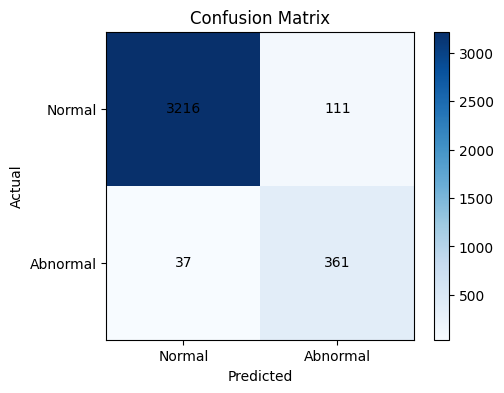

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Split into train/test (stratify keeps the same class ratio in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.2, random_state=42, stratify=labels
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

# class_weight='balanced' compensates for the 89/11 imbalance automatically
clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=42
)

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Normal', 'Abnormal']))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

plt.figure(figsize=(5,4))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0,1], ['Normal','Abnormal'])
plt.yticks([0,1], ['Normal','Abnormal'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j], ha='center', va='center', color='black')
plt.colorbar()
plt.show()

In [12]:
# --- Re-extract features with additional shape-based features ---
features_v2 = []
labels_v2 = []

for rname in record_names:
    rec = all_records[rname]['record']
    ann = all_records[rname]['annotation']
    fs_r = rec.fs
    ecg = bandpass_filter(rec.p_signal[:, 0], fs_r)

    ann_samples = ann.sample
    ann_symbols = ann.symbol

    for i in range(1, len(ann_samples) - 1):
        sym = ann_symbols[i]
        if sym not in valid_beat_symbols:
            continue

        peak = ann_samples[i]
        start, end = peak - window_size, peak + window_size
        if start < 0 or end > len(ecg):
            continue

        beat_segment = ecg[start:end]

        rr_prev = ann_samples[i] - ann_samples[i-1]
        rr_next = ann_samples[i+1] - ann_samples[i]
        rr_ratio = rr_prev / (rr_next + 1e-6)   # relative timing irregularity

        amplitude = np.max(beat_segment) - np.min(beat_segment)
        beat_std = np.std(beat_segment)
        beat_mean = np.mean(beat_segment)

        # QRS width: samples above half the peak's amplitude, around the center
        half_max = np.max(beat_segment) / 2
        above_half = np.where(beat_segment > half_max)[0]
        qrs_width = above_half[-1] - above_half[0] if len(above_half) > 1 else 0

        # Sharpness: max slope near the peak
        slope = np.max(np.abs(np.diff(beat_segment)))

        features_v2.append([rr_prev, rr_next, rr_ratio, amplitude, beat_std, beat_mean, qrs_width, slope])
        labels_v2.append(label_beat(sym))

features_v2 = np.array(features_v2)
labels_v2 = np.array(labels_v2)

print("New feature matrix shape:", features_v2.shape)

# --- Train/test split ---
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    features_v2, labels_v2, test_size=0.2, random_state=42, stratify=labels_v2
)

clf2 = RandomForestClassifier(n_estimators=300, max_depth=12, class_weight='balanced', random_state=42)
clf2.fit(X_train2, y_train2)

# --- Lower threshold from 0.5 to 0.3 to favor catching more abnormal beats ---
probs = clf2.predict_proba(X_test2)[:, 1]
threshold = 0.3
y_pred2 = (probs >= threshold).astype(int)

print(f"\nThreshold: {threshold}")
print("Accuracy:", accuracy_score(y_test2, y_pred2))
print("\nClassification Report:\n", classification_report(y_test2, y_pred2, target_names=['Normal', 'Abnormal']))

cm2 = confusion_matrix(y_test2, y_pred2)
print("Confusion Matrix:\n", cm2)

# Feature importance
feat_names = ['rr_prev', 'rr_next', 'rr_ratio', 'amplitude', 'std', 'mean', 'qrs_width', 'slope']
importances = clf2.feature_importances_
for name, imp in sorted(zip(feat_names, importances), key=lambda x: -x[1]):
    print(f"{name}: {imp:.3f}")

New feature matrix shape: (18625, 8)

Threshold: 0.3
Accuracy: 0.9817449664429531

Classification Report:
               precision    recall  f1-score   support

      Normal       0.99      0.99      0.99      3327
    Abnormal       0.89      0.95      0.92       398

    accuracy                           0.98      3725
   macro avg       0.94      0.97      0.95      3725
weighted avg       0.98      0.98      0.98      3725

Confusion Matrix:
 [[3279   48]
 [  20  378]]
rr_prev: 0.262
qrs_width: 0.249
rr_ratio: 0.184
std: 0.140
amplitude: 0.073
slope: 0.037
rr_next: 0.029
mean: 0.026


Label counts: Counter({np.int64(0): 16634, np.int64(1): 1878, np.int64(2): 113})

Accuracy: 0.9825503355704698

Classification Report:
                 precision    recall  f1-score   support

        Normal       0.99      0.99      0.99      3327
           PVC       0.93      0.93      0.93       376
Other Abnormal       0.67      0.45      0.54        22

      accuracy                           0.98      3725
     macro avg       0.86      0.79      0.82      3725
  weighted avg       0.98      0.98      0.98      3725

Confusion Matrix:
 [[3300   23    4]
 [  25  350    1]
 [  10    2   10]]


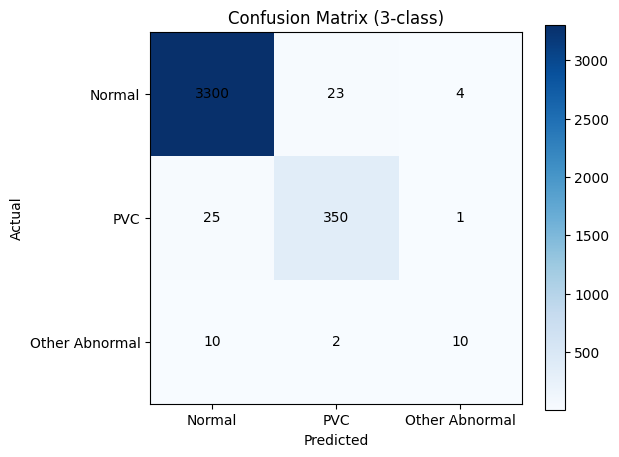

In [13]:
# --- 3-class labeling: Normal / PVC / Other Abnormal ---
def label_multiclass(symbol):
    if symbol == 'N':
        return 0  # Normal
    elif symbol == 'V':
        return 1  # PVC
    else:
        return 2  # Other Abnormal (A, F, a, j, E, etc.)

features_mc = []
labels_mc = []

for rname in record_names:
    rec = all_records[rname]['record']
    ann = all_records[rname]['annotation']
    fs_r = rec.fs
    ecg = bandpass_filter(rec.p_signal[:, 0], fs_r)

    ann_samples = ann.sample
    ann_symbols = ann.symbol

    for i in range(1, len(ann_samples) - 1):
        sym = ann_symbols[i]
        if sym not in valid_beat_symbols:
            continue

        peak = ann_samples[i]
        start, end = peak - window_size, peak + window_size
        if start < 0 or end > len(ecg):
            continue

        beat_segment = ecg[start:end]

        rr_prev = ann_samples[i] - ann_samples[i-1]
        rr_next = ann_samples[i+1] - ann_samples[i]
        rr_ratio = rr_prev / (rr_next + 1e-6)
        amplitude = np.max(beat_segment) - np.min(beat_segment)
        beat_std = np.std(beat_segment)
        beat_mean = np.mean(beat_segment)
        half_max = np.max(beat_segment) / 2
        above_half = np.where(beat_segment > half_max)[0]
        qrs_width = above_half[-1] - above_half[0] if len(above_half) > 1 else 0
        slope = np.max(np.abs(np.diff(beat_segment)))

        features_mc.append([rr_prev, rr_next, rr_ratio, amplitude, beat_std, beat_mean, qrs_width, slope])
        labels_mc.append(label_multiclass(sym))

features_mc = np.array(features_mc)
labels_mc = np.array(labels_mc)

print("Label counts:", Counter(labels_mc))

# --- Train/test split ---
X_train3, X_test3, y_train3, y_test3 = train_test_split(
    features_mc, labels_mc, test_size=0.2, random_state=42, stratify=labels_mc
)

clf3 = RandomForestClassifier(n_estimators=300, max_depth=12, class_weight='balanced', random_state=42)
clf3.fit(X_train3, y_train3)

y_pred3 = clf3.predict(X_test3)

class_names = ['Normal', 'PVC', 'Other Abnormal']
print("\nAccuracy:", accuracy_score(y_test3, y_pred3))
print("\nClassification Report:\n", classification_report(y_test3, y_pred3, target_names=class_names))

cm3 = confusion_matrix(y_test3, y_pred3)
print("Confusion Matrix:\n", cm3)

plt.figure(figsize=(6,5))
plt.imshow(cm3, cmap='Blues')
plt.title("Confusion Matrix (3-class)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0,1,2], class_names)
plt.yticks([0,1,2], class_names)
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm3[i,j], ha='center', va='center', color='black')
plt.colorbar()
plt.show()

In [14]:
# Additional records targeting rare abnormal beat types
new_record_names = ['207', '208', '209', '217', '222', '223', '232']

for rname in new_record_names:
    rec = wfdb.rdrecord(rname, pn_dir='mitdb')
    ann = wfdb.rdann(rname, 'atr', pn_dir='mitdb')
    all_records[rname] = {'record': rec, 'annotation': ann}
    print(f"Loaded {rname}: {len(ann.sample)} annotated beats")

# Update the master record list
record_names = record_names + new_record_names

# Combined beat type counts across all 15 records now
all_symbols = []
for rname in record_names:
    all_symbols.extend(all_records[rname]['annotation'].symbol)

print("\nCombined beat type counts (15 records):", Counter(all_symbols))

Loaded 207: 2385 annotated beats
Loaded 208: 3040 annotated beats
Loaded 209: 3052 annotated beats
Loaded 217: 2280 annotated beats
Loaded 222: 2634 annotated beats
Loaded 223: 2643 annotated beats
Loaded 232: 1816 annotated beats

Combined beat type counts (15 records): Counter({'N': 25188, 'V': 3611, 'A': 2224, '/': 1542, 'L': 1457, '+': 567, 'R': 483, '!': 472, 'F': 402, '~': 302, 'f': 260, 'j': 214, 'E': 106, '|': 57, 'a': 25, 'e': 16, 'x': 11, 'Q': 8, '[': 6, ']': 6, 'S': 2, 'J': 1})


Feature matrix shape: (33699, 9)
Labels shape: (33699,)
Label counts: Counter({np.int64(0): 27334, np.int64(1): 3714, np.int64(2): 2651})

Running 5-Fold Stratified Group Cross-Validation...
Fold 1 Accuracy: 0.5994
Fold 2 Accuracy: 0.8857
Fold 3 Accuracy: 0.6947
Fold 4 Accuracy: 0.9370
Fold 5 Accuracy: 0.8805

================ FINAL CROSS-VALIDATION RESULTS ================

Overall Accuracy:
0.8151

Classification Report:
                precision    recall  f1-score   support

        Normal       0.87      0.91      0.89     27334
           PVC       0.56      0.62      0.59      3714
Other Abnormal       0.19      0.06      0.09      2651

      accuracy                           0.82     33699
     macro avg       0.54      0.53      0.52     33699
  weighted avg       0.78      0.82      0.80     33699



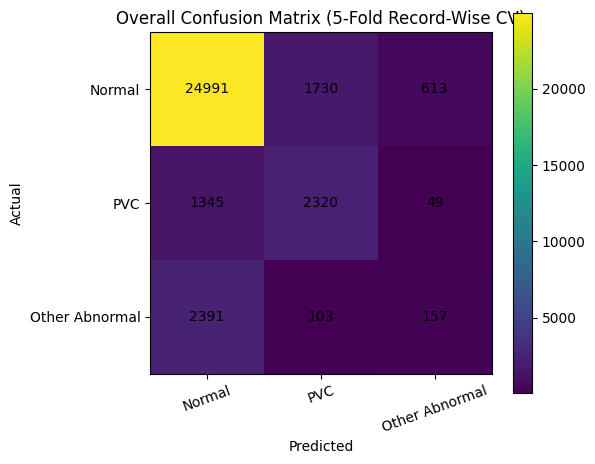


Feature Importance:
qrs_width: 0.233
std: 0.201
rr_prev: 0.160
rr_ratio: 0.090
rr_norm_prev: 0.087
amplitude: 0.063
rr_next: 0.057
mean: 0.055
slope: 0.053


In [15]:
# ============================================================
# FINAL MODEL — RECORD-WISE SPLIT + CORRECT RR FEATURES
# ============================================================

# --- Beat validity + 3-class labeling ---
valid_beat_symbols = {
    'N', 'L', 'R', 'e', 'j',   # Normal
    'V', 'E',                   # PVC / ventricular ectopic
    'A', 'a', 'J', 'S', 'F'    # Other abnormal
}

def label_multiclass(symbol):
    if symbol in {'N', 'L', 'R', 'e', 'j'}:
        return 0          # Normal
    elif symbol in {'V', 'E'}:
        return 1          # PVC / Ventricular ectopic
    else:
        return 2          # Other Abnormal


import numpy as np
from collections import Counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt

# ============================================================
# 1. ENHANCED FEATURE EXTRACTION (WITH PATIENT NORMALIZATION)
# ============================================================

features_mc2 = []
labels_mc2 = []
groups_mc2 = []       # Stores record name for every beat

for rname in record_names:

    rec = all_records[rname]['record']
    ann = all_records[rname]['annotation']
    fs_r = rec.fs

    # Filter ECG
    ecg = bandpass_filter(rec.p_signal[:, 0], fs_r)

    # Keep ONLY valid heartbeat annotations
    valid_indices = [
        i for i, sym in enumerate(ann.symbol)
        if sym in valid_beat_symbols
    ]

    valid_samples = np.array(ann.sample)[valid_indices]
    valid_symbols = np.array(ann.symbol)[valid_indices]

    if len(valid_samples) < 3:
        continue

    # Pre-compute record-level median RR for patient normalization
    all_rr_seconds = np.diff(valid_samples) / fs_r
    patient_median_rr = np.median(all_rr_seconds) if len(all_rr_seconds) > 0 else 1.0

    # Extract features for each valid beat
    for i in range(1, len(valid_samples) - 1):

        sym = valid_symbols[i]
        peak = valid_samples[i]

        start = peak - window_size
        end = peak + window_size

        if start < 0 or end > len(ecg):
            continue

        beat_segment = ecg[start:end]

        # --- Correct RR Features ---
        rr_prev = (valid_samples[i] - valid_samples[i - 1]) / fs_r
        rr_next = (valid_samples[i + 1] - valid_samples[i]) / fs_r
        rr_ratio = rr_prev / (rr_next + 1e-6)

        # New Feature: Patient-relative RR interval
        rr_norm_prev = rr_prev / (patient_median_rr + 1e-6)

        # --- Morphological Features ---
        beat_centered = beat_segment - np.mean(beat_segment)
        amplitude = np.max(beat_centered) - np.min(beat_centered)
        beat_std = np.std(beat_centered)
        beat_mean = np.mean(beat_segment)

        # --- Fixed QRS Width Calculation ---
        abs_beat = np.abs(beat_centered)
        half_max = np.max(abs_beat) / 2.0
        above_half = np.where(abs_beat > half_max)[0]
        qrs_width = (above_half[-1] - above_half[0]) / fs_r if len(above_half) > 1 else 0.0

        # Maximum slope
        slope = np.max(np.abs(np.diff(beat_segment)))

        # Append feature vector
        features_mc2.append([
            rr_prev,
            rr_next,
            rr_ratio,
            rr_norm_prev,
            amplitude,
            beat_std,
            beat_mean,
            qrs_width,
            slope
        ])

        labels_mc2.append(label_multiclass(sym))
        groups_mc2.append(rname)

# Convert to NumPy arrays
features_mc2 = np.array(features_mc2)
labels_mc2 = np.array(labels_mc2)
groups_mc2 = np.array(groups_mc2)

print("Feature matrix shape:", features_mc2.shape)
print("Labels shape:", labels_mc2.shape)
print("Label counts:", Counter(labels_mc2))

# ============================================================
# 2. FULL 5-FOLD RECORD-WISE CROSS-VALIDATION
# ============================================================

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

all_y_test = []
all_y_pred = []

print("\nRunning 5-Fold Stratified Group Cross-Validation...")

for fold, (train_idx, test_idx) in enumerate(sgkf.split(features_mc2, labels_mc2, groups=groups_mc2), 1):
    X_train, X_test = features_mc2[train_idx], features_mc2[test_idx]
    y_train, y_test = labels_mc2[train_idx], labels_mc2[test_idx]

    clf = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    # Store results across all folds
    all_y_test.extend(y_test)
    all_y_pred.extend(y_pred)

    print(f"Fold {fold} Accuracy: {accuracy_score(y_test, y_pred):.4f}")

# ============================================================
# 3. OVERALL EVALUATION & METRICS
# ============================================================

class_names = ['Normal', 'PVC', 'Other Abnormal']

print("\n================ FINAL CROSS-VALIDATION RESULTS ================")

print("\nOverall Accuracy:")
print(f"{accuracy_score(all_y_test, all_y_pred):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        all_y_test,
        all_y_pred,
        target_names=class_names,
        zero_division=0
    )
)

# Confusion Matrix across all combined folds
cm = confusion_matrix(all_y_test, all_y_pred, labels=[0, 1, 2])

plt.figure(figsize=(6, 5))
plt.imshow(cm)

plt.title("Overall Confusion Matrix (5-Fold Record-Wise CV)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1, 2], class_names, rotation=20)
plt.yticks([0, 1, 2], class_names)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.tight_layout()
plt.show()

# ============================================================
# 4. FEATURE IMPORTANCE (Trained on full data)
# ============================================================

feat_names = [
    'rr_prev',
    'rr_next',
    'rr_ratio',
    'rr_norm_prev',
    'amplitude',
    'std',
    'mean',
    'qrs_width',
    'slope'
]

# Fit one model on all data just to display feature importance
clf_final = RandomForestClassifier(n_estimators=300, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1)
clf_final.fit(features_mc2, labels_mc2)

importances = clf_final.feature_importances_

print("\nFeature Importance:")
for name, imp in sorted(zip(feat_names, importances), key=lambda x: -x[1]):
    print(f"{name}: {imp:.3f}")

In [16]:
# ============================================================
# PER-RECORD DIAGNOSTIC — which patients are hardest to classify?
# ============================================================

from collections import defaultdict

# Track predictions alongside which record each beat came from
all_y_test_r = []
all_y_pred_r = []
all_groups_r = []

for fold, (train_idx, test_idx) in enumerate(sgkf.split(features_mc2, labels_mc2, groups=groups_mc2), 1):
    X_train, X_test = features_mc2[train_idx], features_mc2[test_idx]
    y_train, y_test = labels_mc2[train_idx], labels_mc2[test_idx]
    g_test = groups_mc2[test_idx]

    clf = RandomForestClassifier(
        n_estimators=300, max_depth=12, class_weight='balanced',
        random_state=42, n_jobs=-1
    )
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    all_y_test_r.extend(y_test)
    all_y_pred_r.extend(y_pred)
    all_groups_r.extend(g_test)

all_y_test_r = np.array(all_y_test_r)
all_y_pred_r = np.array(all_y_pred_r)
all_groups_r = np.array(all_groups_r)

# --- Per-record accuracy + label composition ---
print(f"{'Record':<8}{'Accuracy':<10}{'N':<7}{'PVC':<7}{'Other':<7}{'Total'}")
print("-" * 50)

record_stats = []
for rname in sorted(set(all_groups_r), key=lambda x: int(x)):
    mask = all_groups_r == rname
    acc = accuracy_score(all_y_test_r[mask], all_y_pred_r[mask])
    labels_here = all_y_test_r[mask]
    n_count = np.sum(labels_here == 0)
    pvc_count = np.sum(labels_here == 1)
    other_count = np.sum(labels_here == 2)
    total = len(labels_here)
    record_stats.append((rname, acc, n_count, pvc_count, other_count, total))
    print(f"{rname:<8}{acc:<10.3f}{n_count:<7}{pvc_count:<7}{other_count:<7}{total}")

# --- Sort to highlight worst performers ---
print("\n--- Sorted worst to best ---")
for rname, acc, n, pvc, other, total in sorted(record_stats, key=lambda x: x[1]):
    print(f"Record {rname}: {acc:.3f} accuracy ({total} beats, {other} 'Other Abnormal')")

Record  Accuracy  N      PVC    Other  Total
--------------------------------------------------
100     0.995     2237   1      33     2271
101     0.999     1858   0      3      1861
103     0.999     2080   0      2      2082
108     0.549     1738   17     6      1761
200     0.801     1742   825    32     2599
203     0.629     2527   444    3      2974
207     0.866     1542   210    106    1858
208     0.747     1585   992    374    2951
209     0.872     2619   1      383    3003
210     0.938     2421   195    32     2648
217     0.824     244    160    0      404
221     0.972     2029   396    0      2425
222     0.801     2272   0      209    2481
223     0.906     2043   473    87     2603
232     0.225     397    0      1381   1778

--- Sorted worst to best ---
Record 232: 0.225 accuracy (1778 beats, 1381 'Other Abnormal')
Record 108: 0.549 accuracy (1761 beats, 6 'Other Abnormal')
Record 203: 0.629 accuracy (2974 beats, 3 'Other Abnormal')
Record 208: 0.747 accuracy (2951

In [17]:
# ============================================================
# STEP 2 — Detailed diagnosis of Record 232
# ============================================================

import pandas as pd
from collections import Counter
from sklearn.metrics import confusion_matrix, classification_report

class_names = ['Normal', 'PVC', 'Other Abnormal']
id_to_name = {0: 'Normal', 1: 'PVC', 2: 'Other Abnormal'}

# Find all predictions belonging to Record 232
mask_232 = all_groups_r == "232"
y_true_232 = all_y_test_r[mask_232]
y_pred_232 = all_y_pred_r[mask_232]

print("Record 232")
print("==========")
print("Total beats:", len(y_true_232))
print("Accuracy:", round((y_true_232 == y_pred_232).mean(), 3))

print("\nRaw annotation symbols in the record (before grouping):")
print(Counter(all_records['232']['annotation'].symbol))

print("\nConfusion Matrix (rows = actual, cols = predicted):")
cm_232 = confusion_matrix(y_true_232, y_pred_232, labels=[0, 1, 2])
print(pd.DataFrame(cm_232,
                   index=[f"true {n}" for n in class_names],
                   columns=[f"pred {n}" for n in class_names]))

print("\nClassification Report:")
print(classification_report(
    y_true_232, y_pred_232,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

print("\nTrue class counts:")
print(pd.Series(y_true_232).map(id_to_name).value_counts())

print("\nPredicted class counts:")
print(pd.Series(y_pred_232).map(id_to_name).value_counts())

Record 232
Total beats: 1778
Accuracy: 0.225

Raw annotation symbols in the record (before grouping):
Counter({'A': 1382, 'R': 397, '~': 35, '+': 1, 'j': 1})

Confusion Matrix (rows = actual, cols = predicted):
                     pred Normal  pred PVC  pred Other Abnormal
true Normal                  397         0                    0
true PVC                       0         0                    0
true Other Abnormal         1378         0                    3

Classification Report:
                precision    recall  f1-score   support

        Normal       0.22      1.00      0.37       397
           PVC       0.00      0.00      0.00         0
Other Abnormal       1.00      0.00      0.00      1381

      accuracy                           0.22      1778
     macro avg       0.41      0.33      0.12      1778
  weighted avg       0.83      0.22      0.08      1778


True class counts:
Other Abnormal    1381
Normal             397
Name: count, dtype: int64

Predicted class count

In [18]:
# ============================================================
# STEP 3 — Compare features of Record 232
# ============================================================

import pandas as pd
import numpy as np

id_to_name = {0: 'Normal', 1: 'PVC', 2: 'Other Abnormal'}

# Build a DataFrame from the NumPy feature matrix
df_all = pd.DataFrame(features_mc2, columns=feat_names)
df_all["label"] = labels_mc2
df_all["record"] = groups_mc2

is_232 = df_all["record"] == "232"
df_232 = df_all[is_232].drop(columns="record")
df_other = df_all[~is_232].drop(columns="record")

print("Record 232 feature statistics")
print("============================")
print(df_232.groupby("label").agg(["mean", "std"]).T)

print("\n\nNumber of samples in each class (232):")
print(df_232["label"].map(id_to_name).value_counts())

print("\n\nFeature medians — Record 232:")
print(df_232.groupby("label").median().T.rename(columns=id_to_name))

print("\n\nFeature medians — all OTHER records:")
print(df_other.groupby("label").median().T.rename(columns=id_to_name))

# Ratio of 232 median to others' median, per class (1.0 = same)
med_232 = df_232.groupby("label").median()
med_oth = df_other.groupby("label").median()
ratio = (med_232 / med_oth).T.rename(columns=id_to_name)
print("\n\nRatio (232 median / others median):")
print(ratio.round(2))

Record 232 feature statistics
label                     0         2
rr_prev      mean  2.008151  0.727333
             std   0.715813  0.028824
rr_next      mean  1.006563  1.015309
             std   0.625594  0.634095
rr_ratio     mean  2.264641  0.861884
             std   0.683763  0.253581
rr_norm_prev mean  2.717795  0.984359
             std   0.968768  0.039010
amplitude    mean  1.128356  1.132724
             std   0.174480  0.162006
std          mean  0.167577  0.162974
             std   0.023105  0.022286
mean         mean -0.015102 -0.027729
             std   0.010120  0.013376
qrs_width    mean  0.029170  0.033551
             std   0.014967  0.025562
slope        mean  0.215853  0.219982
             std   0.031661  0.030574


Number of samples in each class (232):
label
Other Abnormal    1381
Normal             397
Name: count, dtype: int64


Feature medians — Record 232:
label           Normal  Other Abnormal
rr_prev       1.872222        0.730556
rr_next       0.697

In [19]:
# ============================================================
# STEP 4 — Inspect RR values and annotations for Record 232
# ============================================================

import pandas as pd
import numpy as np

# Rebuild the DataFrame from the NumPy feature matrix
df_all = pd.DataFrame(features_mc2, columns=feat_names)
df_all["label"] = labels_mc2
df_all["record"] = groups_mc2

X_232 = df_all[df_all["record"] == "232"].drop(columns="record").reset_index(drop=True)

# --- Attach raw annotation symbols (same filtering as Cell 10) ---
ann = all_records['232']['annotation']
valid_syms = [s for s in ann.symbol if s in valid_beat_symbols]
syms_232 = valid_syms[1:-1]          # loop in Cell 10 skipped first and last beat

if len(syms_232) == len(X_232):
    X_232["symbol"] = syms_232
    show_cols = ["symbol", "rr_prev", "rr_next", "rr_ratio", "rr_norm_prev", "label"]
else:
    print(f"Symbol count ({len(syms_232)}) != feature rows ({len(X_232)}) -> skipping symbols")
    show_cols = ["rr_prev", "rr_next", "rr_ratio", "rr_norm_prev", "label"]

print("First 30 beats of Record 232")
print("============================")
print(X_232[show_cols].head(30).to_string())

print("\n\nRR feature ranges")
print("=================")
for col in ["rr_prev", "rr_next", "rr_ratio", "rr_norm_prev"]:
    print(f"\n{col}")
    print("Min   :", X_232[col].min())
    print("Max   :", X_232[col].max())
    print("Mean  :", X_232[col].mean())
    print("Median:", X_232[col].median())

# --- RR by class, to compare directly with other records ---
print("\n\nMedian RR features by label — Record 232 vs others")
print(df_all.assign(is_232=df_all["record"] == "232")
      .groupby(["is_232", "label"])[["rr_prev", "rr_next", "rr_norm_prev"]]
      .median())

First 30 beats of Record 232
   symbol   rr_prev   rr_next  rr_ratio  rr_norm_prev  label
0       A  0.683333  0.730556  0.935360      0.924811      2
1       A  0.730556  1.830556  0.399089      0.988720      2
2       R  1.830556  0.677778  2.700816      2.477440      0
3       A  0.677778  0.702778  0.964426      0.917292      2
4       A  0.702778  1.869444  0.375928      0.951127      2
5       R  1.869444  0.658333  2.839658      2.530072      0
6       A  0.658333  1.669444  0.394343      0.890976      2
7       R  1.669444  0.672222  2.483467      2.259395      0
8       A  0.672222  1.672222  0.401993      0.909773      2
9       R  1.672222  0.666667  2.508330      2.263155      0
10      A  0.666667  1.638889  0.406779      0.902254      2
11      R  1.638889  0.675000  2.427980      2.218042      0
12      A  0.675000  0.752778  0.896678      0.913533      2
13      A  0.752778  1.741667  0.432217      1.018796      2
14      R  1.741667  0.663889  2.623427      2.357140   

In [20]:
# ============================================================
# STEP 5 — Other Abnormal recall by record
# ============================================================

import numpy as np

OTHER = 2   # class id for "Other Abnormal"

records = sorted(set(all_groups_r), key=lambda x: int(x))

print("Other Abnormal Recall by Record")
print("================================")
print(
    f"{'Record':<10}"
    f"{'Recall':<10}"
    f"{'Actual Other':<15}"
    f"{'Correct':<10}"
    f"{'->Normal':<10}"
    f"{'->PVC':<8}"
)
print("-" * 63)

tot_other = 0
tot_correct = 0

for record in records:

    mask = all_groups_r == record

    y_true_rec = all_y_test_r[mask]
    y_pred_rec = all_y_pred_r[mask]

    # Select only actual Other Abnormal beats
    other_mask = y_true_rec == OTHER

    total_other = int(other_mask.sum())

    if total_other == 0:
        continue

    preds = y_pred_rec[other_mask]

    # Correctly predicted Other Abnormal
    correct = int((preds == OTHER).sum())

    # Misclassified as Normal
    to_normal = int((preds == 0).sum())

    # Misclassified as PVC
    to_pvc = int((preds == 1).sum())

    recall = correct / total_other

    print(
        f"{record:<10}"
        f"{recall:<10.3f}"
        f"{total_other:<15}"
        f"{correct:<10}"
        f"{to_normal:<10}"
        f"{to_pvc:<8}"
    )

    tot_other += total_other
    tot_correct += correct

print("-" * 63)

overall_recall = tot_correct / tot_other if tot_other > 0 else 0

print(
    f"{'TOTAL':<10}"
    f"{overall_recall:<10.3f}"
    f"{tot_other:<15}"
    f"{tot_correct:<10}"
)

Other Abnormal Recall by Record
Record    Recall    Actual Other   Correct   ->Normal  ->PVC   
---------------------------------------------------------------
100       0.667     33             22        11        0       
101       0.333     3              1         2         0       
103       0.000     2              0         2         0       
108       0.167     6              1         2         3       
200       0.000     32             0         32        0       
203       0.000     3              0         0         3       
207       0.000     106            0         105       1       
208       0.000     374            0         283       91      
209       0.000     383            0         383       0       
210       0.094     32             3         29        0       
222       0.584     209            122       85        2       
223       0.057     87             5         79        3       
232       0.002     1381           3         1378      0       
--------

In [21]:
# ============================================================
# STEP 6 — Compare feature distributions across classes
# ============================================================

import pandas as pd
import numpy as np

feature_names = [
    "rr_prev", "rr_next", "rr_ratio", "rr_norm_prev",
    "amplitude", "std", "mean", "qrs_width", "slope"
]

df_features = pd.DataFrame(features_mc2, columns=feature_names)
df_features["label"] = labels_mc2
df_features["record"] = groups_mc2

id_to_name = {0: 'Normal', 1: 'PVC', 2: 'Other Abnormal'}

print("Feature statistics by class")
print("===========================")
stats = df_features.groupby("label")[feature_names].agg(["mean", "median", "std"])
print(stats.to_string())

print("\n\nClass counts:")
print(df_features["label"].map(id_to_name).value_counts())

print("\n\nMedian ratios vs Normal (pooled, all records)")
print("=============================================")
medians = df_features.groupby("label")[feature_names].median()

print(f"{'feature':<15}{'Normal':>12}{'PVC':>12}{'Other':>12}{'PVC/N':>9}{'Other/N':>9}")
for f in feature_names:
    n, p, o = medians.loc[0, f], medians.loc[1, f], medians.loc[2, f]
    r_p = p / n if n != 0 else np.nan
    r_o = o / n if n != 0 else np.nan
    print(f"{f:<15}{n:>12.4f}{p:>12.4f}{o:>12.4f}{r_p:>9.2f}{r_o:>9.2f}")

# --- Within-record comparison: Other vs Normal inside the same patient ---
print("\n\nWithin-record median ratio (Other / Normal), per feature")
print("=========================================================")
rows = {}
for rec, g in df_features.groupby("record"):
    n_med = g[g["label"] == 0][feature_names].median()
    o_grp = g[g["label"] == 2]
    if len(o_grp) >= 10 and (g["label"] == 0).sum() >= 10:   # need enough beats of both
        rows[f"{rec} (n={len(o_grp)})"] = (o_grp[feature_names].median() / n_med).round(2)

print(pd.DataFrame(rows).T.to_string())

Feature statistics by class
        rr_prev                       rr_next                      rr_ratio                     rr_norm_prev                     amplitude                           std                          mean                     qrs_width                         slope                    
           mean    median       std      mean    median       std      mean    median       std         mean    median       std      mean    median       std      mean    median       std      mean    median       std      mean    median       std      mean    median       std
label                                                                                                                                                                                                                                                                                 
0      0.813833  0.775000  0.741523  0.762501  0.719444  0.944999  1.123764  1.016459  0.927709     1.081401  1.015935  0.884974  1.634

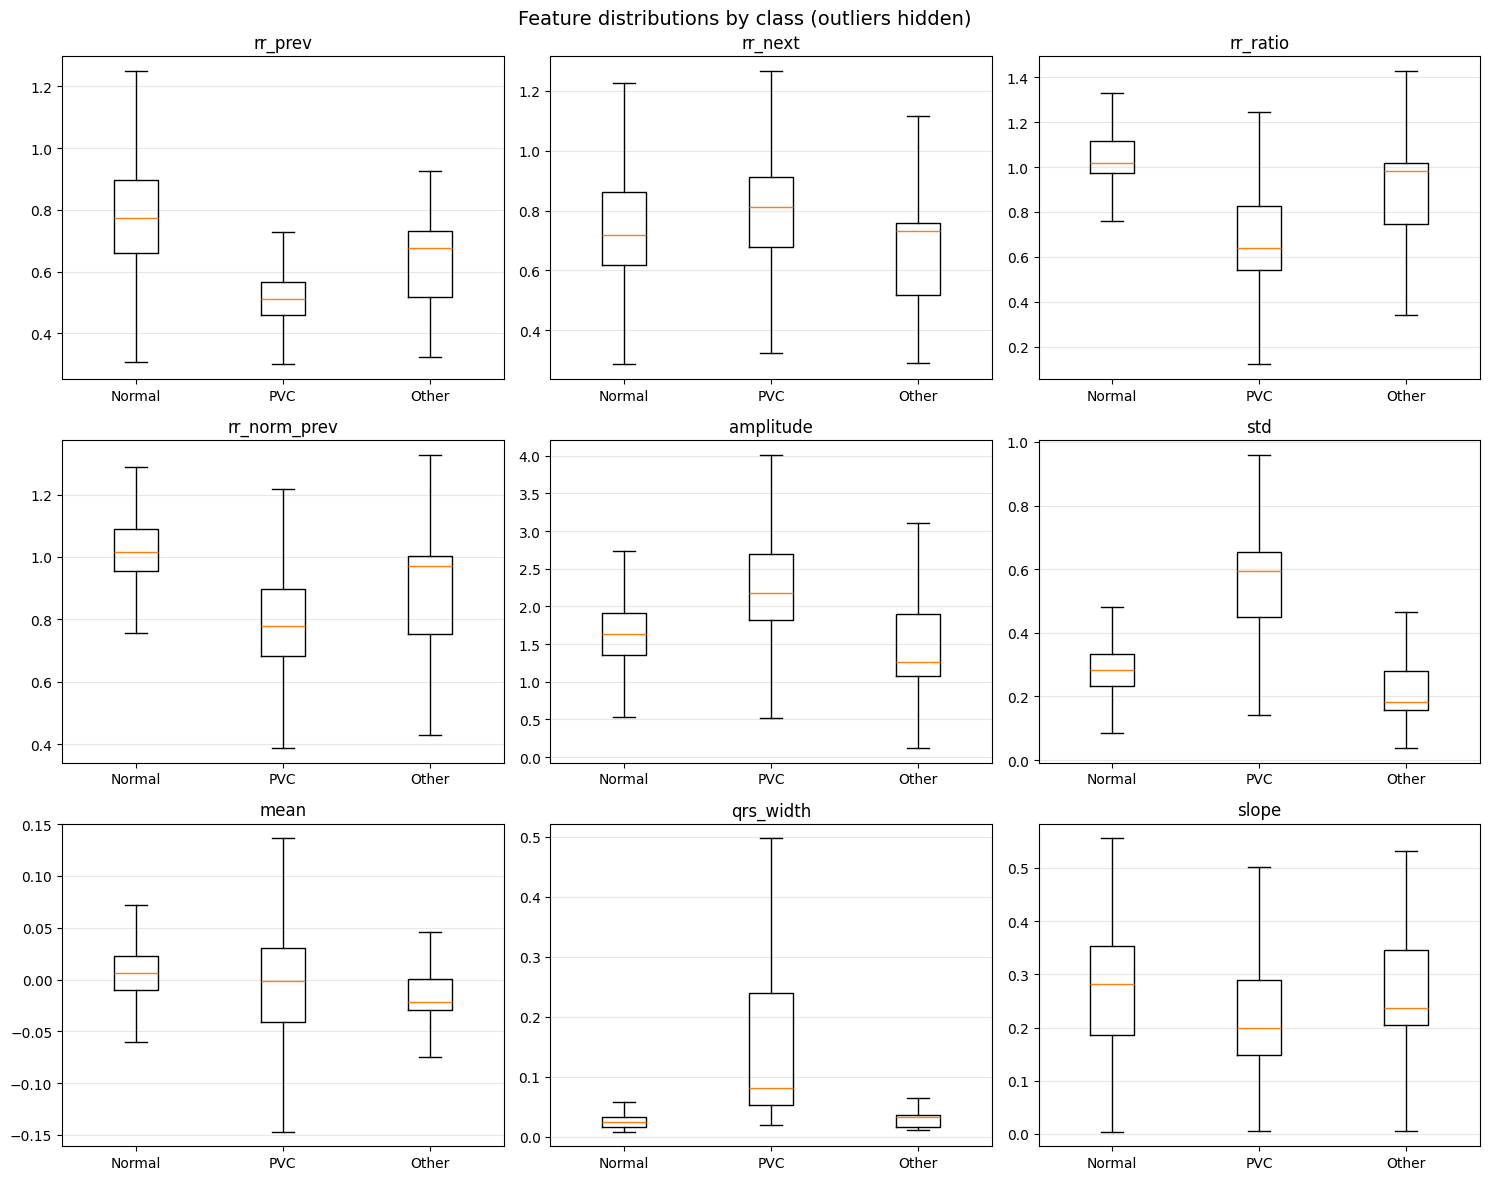

In [22]:
# ============================================================
# STEP 7 — Visualize feature distributions across classes
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

feature_names = [
    "rr_prev", "rr_next", "rr_ratio", "rr_norm_prev",
    "amplitude", "std", "mean", "qrs_width", "slope"
]

class_names = {0: "Normal", 1: "PVC", 2: "Other Abnormal"}
tick_labels = ["Normal", "PVC", "Other"]

df_plot = pd.DataFrame(features_mc2, columns=feature_names)
df_plot["label"] = labels_mc2
df_plot["class_name"] = df_plot["label"].map(class_names)

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, feature in zip(axes.ravel(), feature_names):
    data = [df_plot.loc[df_plot["label"] == k, feature] for k in (0, 1, 2)]

    ax.boxplot(data, showfliers=False)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(tick_labels)
    ax.set_title(feature)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Feature distributions by class (outliers hidden)", fontsize=14)
plt.tight_layout()
plt.show()

In [23]:
# ============================================================
# STEP 8 — Binary Normal vs Abnormal benchmark
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold

# 0 = Normal, 1 = Abnormal (PVC + Other Abnormal)
X_binary = features_mc2
y_binary = np.where(labels_mc2 == 0, 0, 1)
groups_binary = np.array(groups_mc2)

print("Binary class counts:")
print(pd.Series(y_binary).map({0: "Normal", 1: "Abnormal"}).value_counts())

sgkf_binary = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

all_y_binary, all_pred_binary, fold_accuracies = [], [], []

# Split on the 3-class labels so folds match Cell 10 exactly
for fold, (train_idx, test_idx) in enumerate(
    sgkf_binary.split(X_binary, labels_mc2, groups_binary), start=1
):
    X_train, X_test = X_binary[train_idx], X_binary[test_idx]
    y_train, y_test = y_binary[train_idx], y_binary[test_idx]

    model_binary = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
    model_binary.fit(X_train, y_train)
    y_pred = model_binary.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    fold_accuracies.append(acc)
    all_y_binary.extend(y_test)
    all_pred_binary.extend(y_pred)

    held_out = sorted(set(groups_binary[test_idx]), key=int)
    print(f"Fold {fold} accuracy: {acc:.4f}   test records: {held_out}")

print("\n==========================================")
print("BINARY MODEL — OVERALL RESULTS")
print("==========================================")
print(f"\nOverall accuracy: {accuracy_score(all_y_binary, all_pred_binary):.4f}")

print("\nClassification Report:")
print(classification_report(all_y_binary, all_pred_binary,
                            target_names=["Normal", "Abnormal"], digits=4))

print("\nConfusion Matrix (rows = actual, cols = predicted):")
print(confusion_matrix(all_y_binary, all_pred_binary))

print(f"\nMean fold accuracy: {np.mean(fold_accuracies):.4f}")

Binary class counts:
Normal      27334
Abnormal     6365
Name: count, dtype: int64
Fold 1 accuracy: 0.5455   test records: [np.str_('108'), np.str_('203')]
Fold 2 accuracy: 0.9284   test records: [np.str_('200'), np.str_('209'), np.str_('221'), np.str_('223')]
Fold 3 accuracy: 0.6896   test records: [np.str_('100'), np.str_('208'), np.str_('232')]
Fold 4 accuracy: 0.9364   test records: [np.str_('103'), np.str_('207'), np.str_('210')]
Fold 5 accuracy: 0.8666   test records: [np.str_('101'), np.str_('217'), np.str_('222')]

BINARY MODEL — OVERALL RESULTS

Overall accuracy: 0.8179

Classification Report:
              precision    recall  f1-score   support

      Normal     0.8776    0.9011    0.8892     27334
    Abnormal     0.5201    0.4605    0.4885      6365

    accuracy                         0.8179     33699
   macro avg     0.6989    0.6808    0.6889     33699
weighted avg     0.8101    0.8179    0.8135     33699


Confusion Matrix (rows = actual, cols = predicted):
[[24630  2

In [24]:
# ============================================================
# STEP 9 — Binary model performance by record
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

record_results = []

# Same settings and same split labels as Step 8, so folds are identical
sgkf_binary_diag = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, test_idx) in enumerate(
    sgkf_binary_diag.split(X_binary, labels_mc2, groups_binary), start=1
):
    X_train, X_test = X_binary[train_idx], X_binary[test_idx]
    y_train, y_test = y_binary[train_idx], y_binary[test_idx]
    groups_test = groups_binary[test_idx]

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    for record in np.unique(groups_test):
        mask = groups_test == record
        actual = y_test[mask]
        predicted = y_pred[mask]

        abnormal_mask = actual == 1
        abnormal_count = int(abnormal_mask.sum())

        if abnormal_count > 0:
            abnormal_correct = int((predicted[abnormal_mask] == 1).sum())
            abnormal_recall = abnormal_correct / abnormal_count
            abnormal_to_normal = int((predicted[abnormal_mask] == 0).sum())
        else:
            abnormal_correct, abnormal_recall, abnormal_to_normal = 0, np.nan, 0

        # Normal beats wrongly flagged (false alarms)
        normal_mask = actual == 0
        false_alarms = int((predicted[normal_mask] == 1).sum())

        record_results.append({
            "Record": record,
            "Fold": fold,
            "Accuracy": accuracy_score(actual, predicted),
            "Normal": int(normal_mask.sum()),
            "Abnormal": abnormal_count,
            "Abnormal Recall": abnormal_recall,
            "Correct Abnormal": abnormal_correct,
            "Abnormal -> Normal": abnormal_to_normal,
            "Normal -> Abnormal": false_alarms
        })

record_df = pd.DataFrame(record_results).sort_values(
    "Abnormal Recall", na_position="last"
)

print("\nBINARY MODEL — PERFORMANCE BY RECORD")
print("====================================")
print(
    record_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.3f}".format,
            "Abnormal Recall": lambda x: "N/A" if pd.isna(x) else f"{x:.3f}"
        }
    )
)

# Sanity check: totals should match the Step 8 confusion matrix
print("\nTotals across records:")
print("Abnormal missed  :", record_df["Abnormal -> Normal"].sum())
print("False alarms     :", record_df["Normal -> Abnormal"].sum())


BINARY MODEL — PERFORMANCE BY RECORD
Record  Fold Accuracy  Normal  Abnormal Abnormal Recall  Correct Abnormal  Abnormal -> Normal  Normal -> Abnormal
   103     4    0.999    2080         2           0.000                 0                   2                   0
   232     3    0.224     397      1381           0.001                 2                1379                   0
   209     2    0.872    2619       384           0.003                 1                 383                   2
   210     4    0.930    2421       227           0.242                55                 172                  13
   207     4    0.875    1542       316           0.301                95                 221                  11
   101     5    0.999    1858         3           0.333                 1                   2                   0
   100     3    0.991    2237        34           0.412                14                  20                   0
   208     3    0.738    1585      1366           

In [25]:
# ============================================================
# STEP 10 — Investigate difficult records 208, 209 and 232
# ============================================================

import pandas as pd
import numpy as np
from collections import Counter

feature_names = [
    "rr_prev", "rr_next", "rr_ratio", "rr_norm_prev",
    "amplitude", "std", "mean", "qrs_width", "slope"
]

df_diag = pd.DataFrame(features_mc2, columns=feature_names)
df_diag["label"] = labels_mc2
df_diag["record"] = np.array(groups_mc2)
df_diag["binary_label"] = np.where(df_diag["label"] == 0, 0, 1)

def safe_ratio(a, b):
    r = a / b
    return r.replace([np.inf, -np.inf], np.nan)

for record in ["208", "209", "232"]:

    print("\n" + "=" * 70)
    print(f"RECORD {record}")
    print("=" * 70)

    record_data = df_diag[df_diag["record"] == record]
    record_abnormal = record_data[record_data["binary_label"] == 1]
    record_normal = record_data[record_data["binary_label"] == 0]
    other_abnormal = df_diag[(df_diag["record"] != record) &
                             (df_diag["binary_label"] == 1)]

    print(f"\nBeats in Record {record}: {len(record_data)} "
          f"(normal {len(record_normal)}, abnormal {len(record_abnormal)})")
    print(f"Abnormal beats in all other records: {len(other_abnormal)}")

    # --- What are the abnormal beats, by raw annotation symbol? ---
    ann = all_records[record]['annotation']
    valid_syms = [s for s in ann.symbol if s in valid_beat_symbols][1:-1]
    if len(valid_syms) == len(record_data):
        syms = np.array(valid_syms)
        print("\nRaw symbols of ABNORMAL beats:",
              dict(Counter(syms[(record_data["binary_label"] == 1).values])))
        print("Raw symbols of NORMAL beats  :",
              dict(Counter(syms[(record_data["binary_label"] == 0).values])))
    else:
        print("\n(symbol count doesn't match feature rows - skipping symbol breakdown)")

    if len(record_abnormal) == 0:
        print("No abnormal beats in this record - skipping comparisons.")
        continue

    # --- Record abnormal vs other records' abnormal ---
    print(f"\nMedian features: Record {record} abnormal vs other records' abnormal")
    print("-" * 70)
    comparison = pd.DataFrame({
        f"Record {record}": record_abnormal[feature_names].median(),
        "Other records": other_abnormal[feature_names].median()
    })
    comparison["Ratio"] = safe_ratio(comparison[f"Record {record}"],
                                     comparison["Other records"])
    print(comparison.round(4).to_string())

    # --- Record abnormal vs record normal ---
    print("\n\nWithin record: abnormal vs normal")
    print("-" * 70)
    within_record = pd.DataFrame({
        f"Record {record} Normal": record_normal[feature_names].median(),
        f"Record {record} Abnormal": record_abnormal[feature_names].median()
    })
    within_record["Abnormal / Normal"] = safe_ratio(
        within_record[f"Record {record} Abnormal"],
        within_record[f"Record {record} Normal"]
    )
    print(within_record.round(4).to_string())


RECORD 208

Beats in Record 208: 2951 (normal 1585, abnormal 1366)
Abnormal beats in all other records: 4999

Raw symbols of ABNORMAL beats: {np.str_('V'): 992, np.str_('F'): 372, np.str_('S'): 2}
Raw symbols of NORMAL beats  : {np.str_('N'): 1585}

Median features: Record 208 abnormal vs other records' abnormal
----------------------------------------------------------------------
              Record 208  Other records   Ratio
rr_prev           0.5389         0.5472  0.9848
rr_next           0.6667         0.7583  0.8791
rr_ratio          0.7850         0.7297  1.0758
rr_norm_prev      0.9327         0.7891  1.1820
amplitude         2.2481         1.6568  1.3569
std               0.6122         0.2983  2.0522
mean              0.0022        -0.0204 -0.1096
qrs_width         0.0806         0.0417  1.9333
slope             0.2124         0.2221  0.9560


Within record: abnormal vs normal
----------------------------------------------------------------------
              Record 208 No

In [26]:
# ============================================================
# STEP 11 — Add record-relative morphology features
# ============================================================

import pandas as pd
import numpy as np

base_features = [
    "rr_prev", "rr_next", "rr_ratio", "rr_norm_prev",
    "amplitude", "std", "mean", "qrs_width", "slope"
]

df_rel = pd.DataFrame(features_mc2, columns=base_features)
df_rel["label"] = labels_mc2
df_rel["record"] = np.array(groups_mc2)

morphology_features = ["amplitude", "std", "qrs_width", "slope"]
relative_features = [f + "_rel" for f in morphology_features]

for feature in morphology_features:
    record_median = df_rel.groupby("record")[feature].transform("median")
    record_median = record_median.replace(0, np.nan)      # avoid division by zero
    df_rel[feature + "_rel"] = df_rel[feature] / record_median

print("New relative features:", relative_features)
print("NaNs created:", int(df_rel[relative_features].isna().sum().sum()))

print("\nFeature statistics by class:")
print(
    df_rel[["label"] + relative_features]
    .groupby("label")
    .agg(["mean", "median", "std"])
    .to_string()
)

for rec in ["209", "232"]:
    print(f"\nRecord {rec} (median by class):")
    print(
        df_rel[df_rel["record"] == rec][["label"] + relative_features]
        .groupby("label")
        .median()
    )

# Feature matrix with the new columns, for retraining in the next step
all_feature_names = base_features + relative_features
features_mc3 = df_rel[all_feature_names].fillna(1.0).values   # NaN -> 1.0 (= "same as record baseline")
print("\nfeatures_mc3 shape:", features_mc3.shape)

New relative features: ['amplitude_rel', 'std_rel', 'qrs_width_rel', 'slope_rel']
NaNs created: 0

Feature statistics by class:
      amplitude_rel                       std_rel                     qrs_width_rel                     slope_rel                    
               mean    median       std      mean    median       std          mean    median       std      mean    median       std
label                                                                                                                                
0          0.972592  0.989571  0.153037  0.975735  0.985142  0.170323      1.114715  1.000000  1.138388  0.985061  1.004422  0.171892
1          1.252260  1.137824  0.431404  1.709119  1.746180  0.629372      4.557570  3.857143  3.449546  0.812667  0.680199  0.386212
2          1.041945  1.040894  0.195109  1.092505  1.044496  0.282562      1.134544  1.000000  1.149019  1.020185  1.036321  0.169452

Record 209 (median by class):
       amplitude_rel   std_rel  qrs_w

In [27]:
# ============================================================
# STEP 12 — Diagnostic test: original vs relative features
# ============================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score
from sklearn.model_selection import StratifiedGroupKFold

original_features = [
    "rr_prev", "rr_next", "rr_ratio", "rr_norm_prev",
    "amplitude", "std", "mean", "qrs_width", "slope"
]
relative_features = ["amplitude_rel", "std_rel", "qrs_width_rel", "slope_rel"]

X_orig = df_rel[original_features].values
X_exp = df_rel[original_features + relative_features].fillna(1.0).values

y_bin = np.where(labels_mc2 == 0, 0, 1)
groups = np.array(groups_mc2)

print("Original shape:", X_orig.shape, "| Expanded shape:", X_exp.shape)

# Same split as Steps 8/9: stratify on the 3-class labels
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

def make_model():
    return RandomForestClassifier(n_estimators=300, max_depth=12,
                                  class_weight="balanced", random_state=42, n_jobs=-1)

results = {"original": {"y": [], "pred": [], "acc": []},
           "expanded": {"y": [], "pred": [], "acc": []}}

for fold, (tr, te) in enumerate(sgkf.split(X_orig, labels_mc2, groups), start=1):
    test_records = sorted(set(groups[te]), key=int)
    line = f"Fold {fold}  test records: {test_records}"

    for name, X in (("original", X_orig), ("expanded", X_exp)):
        m = make_model().fit(X[tr], y_bin[tr])
        pred = m.predict(X[te])
        acc = accuracy_score(y_bin[te], pred)
        results[name]["y"].extend(y_bin[te])
        results[name]["pred"].extend(pred)
        results[name]["acc"].append(acc)
        line += f" | {name}: {acc:.4f}"
    print(line)

print("\n==========================================")
print("ORIGINAL vs EXPANDED (binary, record-wise CV)")
print("==========================================")

summary = []
for name in ("original", "expanded"):
    y, p = np.array(results[name]["y"]), np.array(results[name]["pred"])
    print(f"\n--- {name.upper()} ---")
    print(classification_report(y, p, target_names=["Normal", "Abnormal"], digits=4))
    print("Confusion matrix (rows = actual, cols = predicted):")
    print(confusion_matrix(y, p))
    summary.append({
        "features": name,
        "accuracy": accuracy_score(y, p),
        "abnormal recall": recall_score(y, p, pos_label=1),
        "normal recall": recall_score(y, p, pos_label=0),
        "mean fold acc": np.mean(results[name]["acc"]),
    })

print("\nSummary:")
print(pd.DataFrame(summary).round(4).to_string(index=False))

print("\nNOTE: Diagnostic only - relative features use each record's full "
      "distribution (including test beats), which a live device won't have.")

Original shape: (33699, 9) | Expanded shape: (33699, 13)
Fold 1  test records: [np.str_('108'), np.str_('203')] | original: 0.5455 | expanded: 0.7704
Fold 2  test records: [np.str_('200'), np.str_('209'), np.str_('221'), np.str_('223')] | original: 0.9284 | expanded: 0.9299
Fold 3  test records: [np.str_('100'), np.str_('208'), np.str_('232')] | original: 0.6896 | expanded: 0.7691
Fold 4  test records: [np.str_('103'), np.str_('207'), np.str_('210')] | original: 0.9364 | expanded: 0.9432
Fold 5  test records: [np.str_('101'), np.str_('217'), np.str_('222')] | original: 0.8666 | expanded: 0.8220

ORIGINAL vs EXPANDED (binary, record-wise CV)

--- ORIGINAL ---
              precision    recall  f1-score   support

      Normal     0.8776    0.9011    0.8892     27334
    Abnormal     0.5201    0.4605    0.4885      6365

    accuracy                         0.8179     33699
   macro avg     0.6989    0.6808    0.6889     33699
weighted avg     0.8101    0.8179    0.8135     33699

Confus

In [29]:
# ============================================================
# STEP 13 — LEAKAGE-FREE, PAST-ONLY RECORD-RELATIVE FEATURES
# ============================================================

import numpy as np
import pandas as pd

base_features = [
    "rr_prev", "rr_next", "rr_ratio", "rr_norm_prev",
    "amplitude", "std", "mean", "qrs_width", "slope"
]

df_causal = pd.DataFrame(features_mc2, columns=base_features)
df_causal["label"] = labels_mc2
df_causal["record"] = np.array(groups_mc2)

morphology_features = ["amplitude", "std", "qrs_width", "slope"]
WINDOW = 50
MIN_PERIODS = 20

def past_median(s):
    """Median of the previous WINDOW beats (current beat excluded)."""
    return s.shift(1).rolling(WINDOW, min_periods=MIN_PERIODS).median()

for feature in morphology_features:
    baseline = df_causal.groupby("record", sort=False)[feature].transform(past_median)
    baseline = baseline.replace(0, np.nan)                 # avoid inf
    df_causal[feature + "_rel"] = df_causal[feature] / baseline

# Causal version of rr_norm_prev (see note below)
rr_base = df_causal.groupby("record", sort=False)["rr_prev"].transform(past_median)
df_causal["rr_norm_prev_causal"] = df_causal["rr_prev"] / rr_base.replace(0, np.nan)

relative_features = [f + "_rel" for f in morphology_features]

print("New relative features:", relative_features + ["rr_norm_prev_causal"])
print("\nShape:", df_causal.shape)

print("\nMissing values (expect ~20 per record from the warm-up):")
print(df_causal[relative_features + ["rr_norm_prev_causal"]].isna().sum())
print("Records:", df_causal["record"].nunique(),
      "-> expected NaNs per feature ≈", df_causal["record"].nunique() * MIN_PERIODS)

# --- Sanity check: baseline for beat k uses only beats k-50 .. k-1 ---
rec = df_causal[df_causal["record"] == "232"].reset_index(drop=True)
k = 100
manual = rec.loc[k - WINDOW:k - 1, "amplitude"].median()
auto = rec.loc[k, "amplitude"] / rec.loc[k, "amplitude_rel"]
print("\nCheck (should match):", round(manual, 6), round(auto, 6))

# Changing FUTURE beats must not change the baseline at beat k
rec2 = rec.copy()
rec2.loc[k + 1:, "amplitude"] *= 10
auto2 = rec2["amplitude"].pipe(past_median).iloc[k]
print("Baseline unchanged by future edits:", np.isclose(auto2, manual))

print("\nFirst 25 rows:")
print(df_causal[["record", "label"] + morphology_features + relative_features].head(25))

New relative features: ['amplitude_rel', 'std_rel', 'qrs_width_rel', 'slope_rel', 'rr_norm_prev_causal']

Shape: (33699, 16)

Missing values (expect ~20 per record from the warm-up):
amplitude_rel          300
std_rel                300
qrs_width_rel          300
slope_rel              300
rr_norm_prev_causal    300
dtype: int64
Records: 15 -> expected NaNs per feature ≈ 300

Check (should match): 1.056933 1.056933
Baseline unchanged by future edits: True

First 25 rows:
   record  label  amplitude       std  qrs_width     slope  amplitude_rel  \
0     100      0   1.438437  0.229617   0.016667  0.263540            NaN   
1     100      0   1.414162  0.209291   0.013889  0.305791            NaN   
2     100      0   1.383891  0.199483   0.013889  0.286660            NaN   
3     100      0   1.286810  0.186439   0.013889  0.273694            NaN   
4     100      0   1.331083  0.199609   0.013889  0.280616            NaN   
5     100      0   1.423199  0.212827   0.016667  0.295473    

In [30]:
# STEP 13B — REMOVE WARM-UP BEATS

relative_features = [
    "amplitude_rel",
    "std_rel",
    "qrs_width_rel",
    "slope_rel",
    "rr_norm_prev_causal"
]

# Keep only rows where all causal features are available
df_causal_valid = df_causal.dropna(
    subset=relative_features
).copy()

print("Original rows:", len(df_causal))
print("Rows after warm-up removal:", len(df_causal_valid))
print("Rows removed:", len(df_causal) - len(df_causal_valid))

print("\nRecords remaining:", df_causal_valid["record"].nunique())

print("\nRows removed per record:")
print(
    df_causal.groupby("record").size()
    - df_causal_valid.groupby("record").size()
)

print("\nMissing values after removal:")
print(df_causal_valid[relative_features].isna().sum())

print("\nClass counts after warm-up removal:")
print(df_causal_valid["label"].value_counts().sort_index())

# Extra check: infinite or extreme values in the causal features
print("\nInf values:", np.isinf(df_causal_valid[relative_features]).sum().sum())
print("\nRange of causal features:")
print(df_causal_valid[relative_features].describe().loc[["min", "50%", "max"]].round(3))

Original rows: 33699
Rows after warm-up removal: 33399
Rows removed: 300

Records remaining: 15

Rows removed per record:
record
100    20
101    20
103    20
108    20
200    20
203    20
207    20
208    20
209    20
210    20
217    20
221    20
222    20
223    20
232    20
dtype: int64

Missing values after removal:
amplitude_rel          0
std_rel                0
qrs_width_rel          0
slope_rel              0
rr_norm_prev_causal    0
dtype: int64

Class counts after warm-up removal:
label
0    27104
1     3661
2     2634
Name: count, dtype: int64

Inf values: 0

Range of causal features:
     amplitude_rel  std_rel  qrs_width_rel  slope_rel  rr_norm_prev_causal
min          0.024    0.034          0.075      0.013                0.209
50%          1.001    1.000          1.000      1.000                1.000
max          3.764    5.403         34.200      3.227              101.004


In [31]:
# ============================================================
# STEP 13C — BUILD CAUSAL FEATURE MATRIX
# ============================================================

import numpy as np

# Baseline set, exactly as in Cell 10 (includes the non-causal rr_norm_prev)
original_features = [
    "rr_prev", "rr_next", "rr_ratio", "rr_norm_prev",
    "amplitude", "std", "mean", "qrs_width", "slope"
]

# Causal set: original features MINUS the leaky rr_norm_prev, PLUS past-only features
causal_features = [
    "amplitude_rel", "std_rel", "qrs_width_rel", "slope_rel",
    "rr_norm_prev_causal"
]
features_causal = [f for f in original_features if f != "rr_norm_prev"] + causal_features

# Both feature sets come from the SAME filtered rows
X_orig_c = df_causal_valid[original_features].to_numpy()
X_causal = df_causal_valid[features_causal].to_numpy()
y_causal = df_causal_valid["label"].to_numpy()
groups_causal = df_causal_valid["record"].to_numpy()

print("Causal features (%d):" % len(features_causal))
for i, f in enumerate(features_causal, 1):
    print(i, f)

print("\nX_orig_c shape:", X_orig_c.shape)
print("X_causal shape:", X_causal.shape)
print("y shape:", y_causal.shape, "| Records:", len(set(groups_causal)))

print("\nClass counts:")
print(df_causal_valid["label"].value_counts().sort_index())

print("\nMissing values:", np.isnan(X_causal).sum())
print("Inf values:", np.isinf(X_causal).sum())
assert "rr_norm_prev" not in features_causal   # guard against the leaky feature

Causal features (13):
1 rr_prev
2 rr_next
3 rr_ratio
4 amplitude
5 std
6 mean
7 qrs_width
8 slope
9 amplitude_rel
10 std_rel
11 qrs_width_rel
12 slope_rel
13 rr_norm_prev_causal

X_orig_c shape: (33399, 9)
X_causal shape: (33399, 13)
y shape: (33399,) | Records: 15

Class counts:
label
0    27104
1     3661
2     2634
Name: count, dtype: int64

Missing values: 0
Inf values: 0


In [32]:
# ============================================================
# STEP 13D — RECORD-WISE CV: ORIGINAL vs CAUSAL FEATURES
# ============================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, confusion_matrix

base8 = ["rr_prev", "rr_next", "rr_ratio", "amplitude", "std", "mean", "qrs_width", "slope"]
causal_extra = ["amplitude_rel", "std_rel", "qrs_width_rel", "slope_rel", "rr_norm_prev_causal"]

feature_sets = {
    "orig9 (Cell 10, leaky rr_norm_prev)": base8[:3] + ["rr_norm_prev"] + base8[3:],
    "orig8 (no rr_norm_prev)": base8,
    "causal13": base8 + causal_extra,
}

y = df_causal_valid["label"].to_numpy()
groups = df_causal_valid["record"].to_numpy()
class_names = ["Normal", "PVC", "Other Abnormal"]

SEEDS = [42, 1, 7]
rows = []

for seed in SEEDS:
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    splits = list(sgkf.split(df_causal_valid, y, groups))   # same folds for every feature set

    for name, cols in feature_sets.items():
        X = df_causal_valid[cols].to_numpy()
        y_all, p_all, fold_acc = [], [], []

        for tr, te in splits:
            m = RandomForestClassifier(n_estimators=300, max_depth=12,
                                       class_weight="balanced",
                                       random_state=42, n_jobs=-1)
            m.fit(X[tr], y[tr])
            pred = m.predict(X[te])
            fold_acc.append(accuracy_score(y[te], pred))
            y_all.extend(y[te]); p_all.extend(pred)

        y_all, p_all = np.array(y_all), np.array(p_all)
        rec = recall_score(y_all, p_all, labels=[0, 1, 2], average=None, zero_division=0)

        rows.append({
            "seed": seed, "features": name,
            "accuracy": accuracy_score(y_all, p_all),
            "macro_f1": f1_score(y_all, p_all, average="macro", zero_division=0),
            "recall_Normal": rec[0], "recall_PVC": rec[1], "recall_Other": rec[2],
            "worst_fold": min(fold_acc),
        })

        if seed == SEEDS[0]:   # detailed report for the first seed only
            print("\n" + "=" * 70)
            print(f"{name}  (seed {seed})")
            print("=" * 70)
            print(classification_report(y_all, p_all, labels=[0, 1, 2],
                                        target_names=class_names, digits=4, zero_division=0))
            print("Confusion matrix (rows = actual, cols = predicted):")
            print(confusion_matrix(y_all, p_all, labels=[0, 1, 2]))

results = pd.DataFrame(rows)
metric_cols = ["accuracy", "macro_f1", "recall_Normal", "recall_PVC", "recall_Other", "worst_fold"]

print("\n\nMEAN over seeds", SEEDS)
print(results.groupby("features")[metric_cols].mean().round(4).to_string())
print("\nSTD over seeds")
print(results.groupby("features")[metric_cols].std().round(4).to_string())


orig9 (Cell 10, leaky rr_norm_prev)  (seed 42)
                precision    recall  f1-score   support

        Normal     0.8701    0.9114    0.8903     27104
           PVC     0.5403    0.6184    0.5767      3661
Other Abnormal     0.2007    0.0623    0.0950      2634

      accuracy                         0.8123     33399
     macro avg     0.5370    0.5307    0.5207     33399
  weighted avg     0.7811    0.8123    0.7932     33399

Confusion matrix (rows = actual, cols = predicted):
[[24703  1810   591]
 [ 1335  2264    62]
 [ 2354   116   164]]

orig8 (no rr_norm_prev)  (seed 42)
                precision    recall  f1-score   support

        Normal     0.8836    0.9124    0.8978     27104
           PVC     0.5684    0.7241    0.6369      3661
Other Abnormal     0.2259    0.0642    0.0999      2634

      accuracy                         0.8248     33399
     macro avg     0.5593    0.5669    0.5449     33399
  weighted avg     0.7972    0.8248    0.8062     33399

Confusion 

In [33]:
# ============================================================
# STEP 14 — PER-RECORD DIAGNOSTIC FOR CAUSAL13 (vs orig8)
# ============================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold

base8 = ["rr_prev", "rr_next", "rr_ratio", "amplitude", "std", "mean", "qrs_width", "slope"]
causal13 = base8 + ["amplitude_rel", "std_rel", "qrs_width_rel", "slope_rel", "rr_norm_prev_causal"]

X13 = df_causal_valid[causal13].to_numpy()
X8 = df_causal_valid[base8].to_numpy()
y = df_causal_valid["label"].to_numpy()
groups = df_causal_valid["record"].to_numpy()

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Out-of-fold predictions, stored in the original row order
pred13 = np.empty_like(y)
pred8 = np.empty_like(y)

for tr, te in sgkf.split(X13, y, groups):
    for X, pred in ((X13, pred13), (X8, pred8)):
        m = RandomForestClassifier(n_estimators=300, max_depth=12,
                                   class_weight="balanced",
                                   random_state=42, n_jobs=-1)
        m.fit(X[tr], y[tr])
        pred[te] = m.predict(X[te])

def recall_of(cls, actual, predicted):
    mask = actual == cls
    return (predicted[mask] == cls).mean() if mask.sum() > 0 else np.nan

rows = []
for rec in sorted(set(groups), key=int):
    m = groups == rec
    a, p13, p8 = y[m], pred13[m], pred8[m]

    rows.append({
        "Record": rec,
        "Total": int(m.sum()),
        "Normal": int((a == 0).sum()),
        "PVC": int((a == 1).sum()),
        "Other": int((a == 2).sum()),
        "Accuracy": (a == p13).mean(),
        "PVC Recall": recall_of(1, a, p13),
        "Other Recall": recall_of(2, a, p13),
        "Other Recall (orig8)": recall_of(2, a, p8),
        "Other -> Normal": int(((a == 2) & (p13 == 0)).sum()),
        "Other -> PVC": int(((a == 2) & (p13 == 1)).sum()),
        "Normal -> Abnormal": int(((a == 0) & (p13 != 0)).sum()),
    })

record_results = pd.DataFrame(rows)

print("=" * 100)
print("CAUSAL13 — OTHER ABNORMAL RECALL BY RECORD (sorted, records with no Other beats last)")
print("=" * 100)
print(record_results.sort_values("Other Recall").round(3).to_string(index=False))

print("\n" + "=" * 100)
print("DIFFICULT RECORDS: 208, 209, 232")
print("=" * 100)
print(record_results[record_results["Record"].isin(["208", "209", "232"])]
      .round(3).to_string(index=False))

# Overall check
print("\nOverall Other recall  causal13: %.3f | orig8: %.3f" % (
    recall_of(2, y, pred13), recall_of(2, y, pred8)))
print("Overall accuracy       causal13: %.3f | orig8: %.3f" % (
    (y == pred13).mean(), (y == pred8).mean()))

CAUSAL13 — OTHER ABNORMAL RECALL BY RECORD (sorted, records with no Other beats last)
Record  Total  Normal  PVC  Other  Accuracy  PVC Recall  Other Recall  Other Recall (orig8)  Other -> Normal  Other -> PVC  Normal -> Abnormal
   101   1841    1838    0      3     0.998         NaN         0.000                 0.000                3             0                   0
   103   2062    2060    0      2     0.999         NaN         0.000                 0.000                2             0                   0
   108   1741    1719   16      6     0.637       0.688         0.000                 0.167                4             2                 621
   203   2954    2510  441      3     0.719       0.946         0.000                 0.000                0             3                 803
   208   2931    1578  981    372     0.840       0.957         0.000                 0.024              263           109                  54
   207   1838    1532  200    106     0.851       0.200 

In [34]:
# ============================================================
# STEP 15 — DETAILED CONFUSION FOR DIFFICULT RECORDS (causal13 vs orig8)
# ============================================================

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, classification_report

base8 = ["rr_prev", "rr_next", "rr_ratio", "amplitude", "std", "mean", "qrs_width", "slope"]
causal13 = base8 + ["amplitude_rel", "std_rel", "qrs_width_rel", "slope_rel", "rr_norm_prev_causal"]

y = df_causal_valid["label"].to_numpy()
groups = df_causal_valid["record"].to_numpy()
feature_sets = {"causal13": df_causal_valid[causal13].to_numpy(),
                "orig8": df_causal_valid[base8].to_numpy()}

# Out-of-fold predictions, same folds and settings as Step 14
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
oof = {name: np.empty_like(y) for name in feature_sets}

for tr, te in sgkf.split(feature_sets["causal13"], y, groups):
    for name, X in feature_sets.items():
        m = RandomForestClassifier(n_estimators=300, max_depth=12,
                                   class_weight="balanced",
                                   random_state=42, n_jobs=-1)
        m.fit(X[tr], y[tr])
        oof[name][te] = m.predict(X[te])

id_to_name = {0: "Normal", 1: "PVC", 2: "Other Abnormal"}
class_names = ["Normal", "PVC", "Other Abnormal"]

for record in ["208", "209", "232"]:          # record IDs are strings
    mask = groups == record
    a = y[mask]
    p = oof["causal13"][mask]

    print("\n" + "=" * 80)
    print(f"RECORD {record}  (causal13)")
    print("=" * 80)
    print(f"Total beats: {mask.sum()}")

    print("\nActual class counts:")
    print(pd.Series(a).map(id_to_name).value_counts())

    print("\nPredicted class counts:")
    print(pd.Series(p).map(id_to_name).value_counts())

    print("\nConfusion matrix (rows = actual, cols = predicted):")
    print(pd.DataFrame(confusion_matrix(a, p, labels=[0, 1, 2]),
                       index=[f"true {n}" for n in class_names],
                       columns=[f"pred {n}" for n in class_names]))

    print("\nClassification report:")
    print(classification_report(a, p, labels=[0, 1, 2],
                                target_names=class_names, zero_division=0))

    # Where do the Other Abnormal beats go? causal13 vs orig8
    other = a == 2
    if other.sum() > 0:
        table = pd.DataFrame({
            name: pd.Series(oof[name][mask][other]).map(id_to_name).value_counts()
            for name in feature_sets
        }).reindex(class_names).fillna(0).astype(int)
        table.index = ["Predicted " + n for n in table.index]
        print(f"\nOther Abnormal beats ({other.sum()}) - where they were predicted:")
        print(table)
    else:
        print("\nNo Other Abnormal beats in this record.")


RECORD 208  (causal13)
Total beats: 2931

Actual class counts:
Normal            1578
PVC                981
Other Abnormal     372
Name: count, dtype: int64

Predicted class counts:
Normal            1829
PVC               1051
Other Abnormal      51
Name: count, dtype: int64

Confusion matrix (rows = actual, cols = predicted):
                     pred Normal  pred PVC  pred Other Abnormal
true Normal                 1524         3                   51
true PVC                      42       939                    0
true Other Abnormal          263       109                    0

Classification report:
                precision    recall  f1-score   support

        Normal       0.83      0.97      0.89      1578
           PVC       0.89      0.96      0.92       981
Other Abnormal       0.00      0.00      0.00       372

      accuracy                           0.84      2931
     macro avg       0.58      0.64      0.61      2931
  weighted avg       0.75      0.84      0.79     